In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
%matplotlib inline

from google.colab import files
import io

In [6]:
df = pd.read_csv("/content/Speed Dating Data.csv", encoding='ISO-8859-1')
df.shape

(8378, 195)

In [7]:
df.head()

,iid,id,gender,idg,condtn,wave,round,position,positin1,order,...,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
4,1,1.0,0,1,1,1,10,7,NaN,7,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN


In [8]:
df['iid'].value_counts()

,count
iid,
552,22
551,22
550,22
549,22
533,22
...,...
138,5
137,5
136,5


In [9]:

import pandas as pd
import numpy as np



print("Dataset shape:", df.shape)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nTarget columns:")
targets = ['dec', 'dec_o', 'match']
display(df[targets].head() if all(c in df.columns for c in targets)
        else "Some expected target columns are missing")

print("\nMissing values in important columns:")
important = [c for c in ['iid', 'pid', 'dec', 'dec_o', 'match',
                          'like', 'prob', 'age', 'age_o']
             if c in df.columns]
display(df[important].isnull().sum())


Dataset shape: (8378, 195)
Total rows: 8378
Total columns: 195

Column names:
['iid', 'id', 'gender', 'idg', 'condtn', 'wave', 'round', 'position', 'positin1', 'order', 'partner', 'pid', 'match', 'int_corr', 'samerace', 'age_o', 'race_o', 'pf_o_att', 'pf_o_sin', 'pf_o_int', 'pf_o_fun', 'pf_o_amb', 'pf_o_sha', 'dec_o', 'attr_o', 'sinc_o', 'intel_o', 'fun_o', 'amb_o', 'shar_o', 'like_o', 'prob_o', 'met_o', 'age', 'field', 'field_cd', 'undergra', 'mn_sat', 'tuition', 'race', 'imprace', 'imprelig', 'from', 'zipcode', 'income', 'goal', 'date', 'go_out', 'career', 'career_c', 'sports', 'tvsports', 'exercise', 'dining', 'museums', 'art', 'hiking', 'gaming', 'clubbing', 'reading', 'tv', 'theater', 'movies', 'concerts', 'music', 'shopping', 'yoga', 'exphappy', 'expnum', 'attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1', 'attr4_1', 'sinc4_1', 'intel4_1', 'fun4_1', 'amb4_1', 'shar4_1', 'attr2_1', 'sinc2_1', 'intel2_1', 'fun2_1', 'amb2_1', 'shar2_1', 'attr3_1', 'sinc3_1', 'fun3_1', '

,iid,id,gender,idg,condtn,wave,round,position,positin1,order,...,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
4,1,1.0,0,1,1,1,10,7,NaN,7,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN



Target columns:


,dec,dec_o,match
0,1,0,0
1,1,0,0
2,1,1,1
3,1,1,1
4,1,1,1



Missing values in important columns:


,0
iid,0
pid,10
dec,0
dec_o,0
match,0
like,240
prob,309
age,95
age_o,104


In [10]:

# ISITMUTUAL? — Dataset Validation

# 1. Verify how match is constructed
expected_match = (
    (df["dec"] == 1) & (df["dec_o"] == 1)
).astype(int)

print("MATCH CONSISTENCY:")
print("Mismatches:", (df["match"] != expected_match).sum())

# 2. Target distribution
print("\nTARGET DISTRIBUTION:")
print(df["match"].value_counts())
print("\nTarget percentages:")
print((df["match"].value_counts(normalize=True) * 100).round(2))

# 3. Decision combinations
print("\nDECISION COMBINATIONS:")
display(pd.crosstab(df["dec"], df["dec_o"]))

# 4. Participants and waves
print("\nUNIQUE PARTICIPANTS:", df["iid"].nunique())
print("UNIQUE PARTNERS:", df["pid"].nunique())
print("NUMBER OF WAVES:", df["wave"].nunique())
print("\nOBSERVATIONS PER WAVE:")
display(df["wave"].value_counts().sort_index())

# 5. Age distribution
print("\nAGE SUMMARY:")
display(df[["age", "age_o"]].describe())

# 6. Check whether each pair appears in both directions
pairs = df.dropna(subset=["iid", "pid"]).copy()

pairs["person_1"] = pairs[["iid", "pid"]].min(axis=1)
pairs["person_2"] = pairs[["iid", "pid"]].max(axis=1)

pair_counts = (
    pairs.groupby(["wave", "person_1", "person_2"])
    .size()
)

print("\nPAIR STRUCTURE:")
print("Total unique pairs:", len(pair_counts))
print("Pairs appearing once:", (pair_counts == 1).sum())
print("Pairs appearing twice:", (pair_counts == 2).sum())
print("Pairs appearing more than twice:", (pair_counts > 2).sum())


MATCH CONSISTENCY:
Mismatches: 0

TARGET DISTRIBUTION:
match
0    6998
1    1380
Name: count, dtype: int64

Target percentages:
match
0    83.53
1    16.47
Name: proportion, dtype: float64

DECISION COMBINATIONS:


dec_o,0,1
dec,,
0,2725,2135
1,2138,1380



UNIQUE PARTICIPANTS: 551
UNIQUE PARTNERS: 551
NUMBER OF WAVES: 21

OBSERVATIONS PER WAVE:


,count
wave,
1,200
2,608
3,200
4,648
5,190
6,50
7,512
8,200
9,800



AGE SUMMARY:


,age,age_o
count,8283.000000,8274.000000
mean,26.358928,26.364999
std,3.566763,3.563648
min,18.000000,18.000000
25%,24.000000,24.000000
50%,26.000000,26.000000
75%,28.000000,28.000000
max,55.000000,55.000000



PAIR STRUCTURE:
Total unique pairs: 4184
Pairs appearing once: 0
Pairs appearing twice: 4184
Pairs appearing more than twice: 0


In [11]:
pair_counts

wave  person_1  person_2
1     1.0       11.0        2
                12.0        2
                13.0        2
                14.0        2
                15.0        2
                           ..
21    530.0     548.0       2
                549.0       2
                550.0       2
                551.0       2
                552.0       2
Length: 4184, dtype: int64

In [12]:
# Check whether every pair has both directional records

direction_counts = (
    pairs.groupby(["wave", "person_1", "person_2"])["iid"]
    .agg(
        unique_iids="nunique",
        total_rows="size"
    )
    .reset_index()
)

print("DIRECTION VALIDATION:")
print("Both directions present:",
      ((direction_counts["unique_iids"] == 2) &
       (direction_counts["total_rows"] == 2)).sum())

print("Only one direction present:",
      (direction_counts["unique_iids"] == 1).sum())

print("Unexpected pair records:",
      (direction_counts["total_rows"] > 2).sum())

DIRECTION VALIDATION:
Both directions present: 4184
Only one direction present: 0
Unexpected pair records: 0


In [13]:
df["match"]

,match
0,0
1,0
2,1
3,1
4,1
...,...
8373,0
8374,0
8375,0
8376,0


In [14]:
# Recalculate expected_match and check for mismatches
expected_match = ((df["dec"] == 1) & (df["dec_o"] == 1)).astype(int)

print(f"Total Mismatches : {(df["match"] != expected_match).sum()}")

Total Mismatches : 0


In [15]:
print("MATCH COUNTS:")
print(df["match"].value_counts())

print("\nMATCH PERCENTAGES:")
print((df["match"].value_counts(normalize=True) * 100).round(2))

# 83.53% of speed-date observations resulted in NO mutual match.
# 16.47% resulted in a mutual YES (both participants wanted to meet again).

MATCH COUNTS:
match
0    6998
1    1380
Name: count, dtype: int64

MATCH PERCENTAGES:
match
0    83.53
1    16.47
Name: proportion, dtype: float64


,missing_count,missing_percentage
num_in_3,7710,92.03
numdat_3,6882,82.14
expnum,6578,78.52
sinc7_2,6423,76.67
amb7_2,6423,76.67
...,...,...
gender,0,0.00
round,0,0.00
position,0,0.00
match,0,0.00


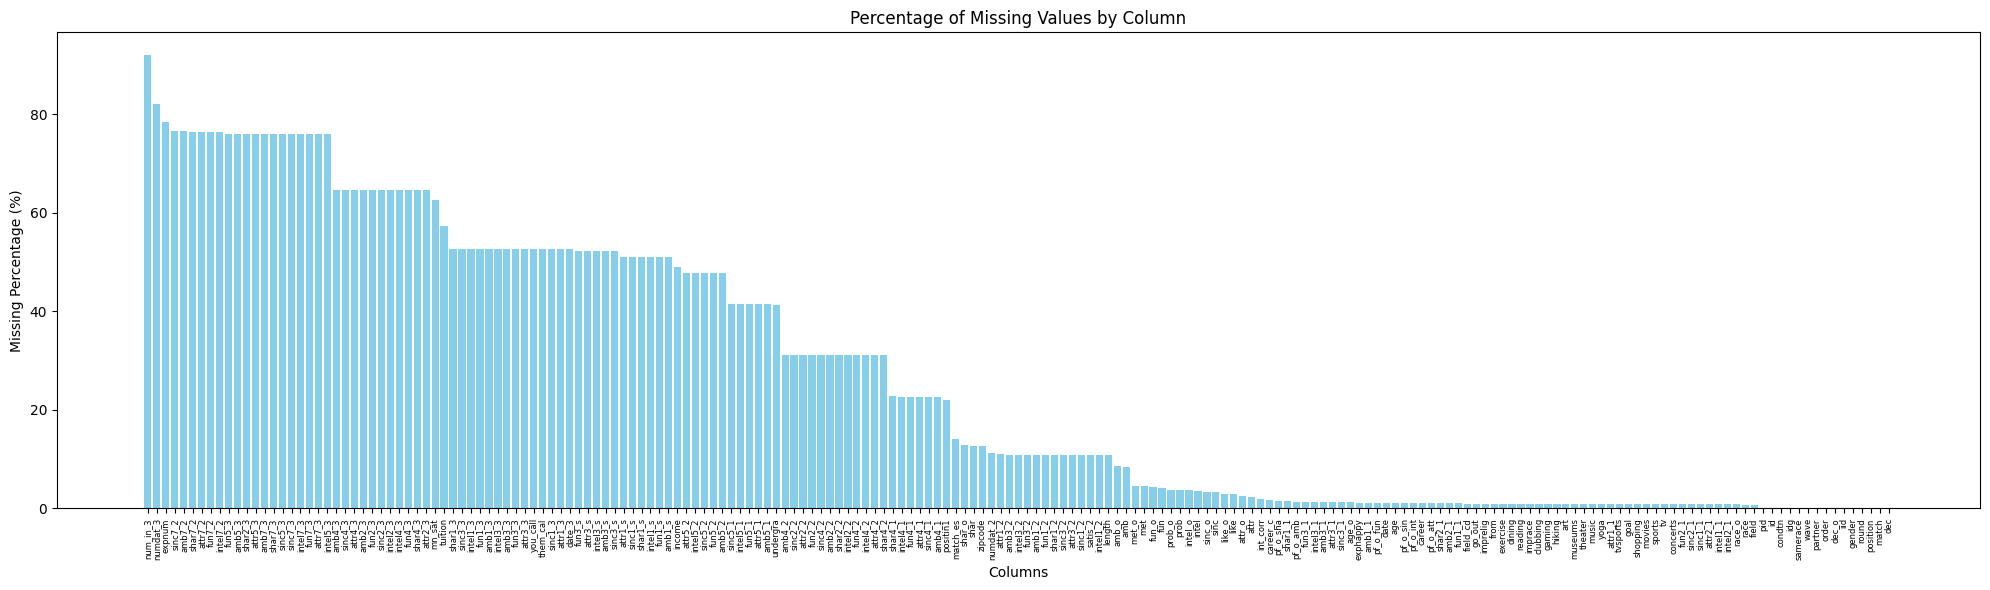

In [16]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (df.isnull().mean() * 100).round(2)
})

# Sort missing values
sorted_missing = missing.sort_values(by="missing_percentage", ascending=False)

# Display the top 25 missing values
display(sorted_missing.head(200))

# Plot missing percentage vs column name
plt.figure(figsize=(20, 6))
plt.bar(sorted_missing.index, sorted_missing["missing_percentage"], color='skyblue')
plt.xticks(rotation=90, fontsize=6)
plt.title("Percentage of Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")
plt.tight_layout()
plt.show()

In [17]:
# Missing values grouped by percentage

print("Columns with more than 50% missing:")
display(
    missing[missing["missing_percentage"] > 50]
)

print("\nColumns with 20-50% missing:")
display(
    missing[
        (missing["missing_percentage"] >= 20) &
        (missing["missing_percentage"] <= 50)
    ]
)

Columns with more than 50% missing:


,missing_count,missing_percentage
mn_sat,5245,62.60
tuition,4795,57.23
expnum,6578,78.52
attr1_s,4282,51.11
sinc1_s,4282,51.11
intel1_s,4282,51.11
fun1_s,4282,51.11
amb1_s,4282,51.11
shar1_s,4282,51.11
attr3_s,4378,52.26



Columns with 20-50% missing:


,missing_count,missing_percentage
positin1,1846,22.03
undergra,3464,41.35
income,4099,48.93
attr4_1,1889,22.55
sinc4_1,1889,22.55
intel4_1,1889,22.55
fun4_1,1889,22.55
amb4_1,1889,22.55
shar4_1,1911,22.81
attr5_1,3472,41.44


In [18]:
# Check whether missingness in a column varies across waves

columns_to_check = [
    "attr1_1",
    "attr1_s",
    "attr7_2",
    "you_call",
    "attr1_3"
]

for col in columns_to_check:
    print(f"\nMissing percentage by wave: {col}")

    display(
        df.groupby("wave")[col]
        .apply(lambda x: x.isna().mean() * 100)
        .round(1)
    )


Missing percentage by wave: attr1_1


,attr1_1
wave,
1,0.0
2,2.6
3,10.0
4,0.0
5,0.0
6,10.0
7,0.0
8,0.0
9,0.0



Missing percentage by wave: attr1_s


,attr1_s
wave,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,0.0
7,18.8
8,0.0
9,2.5



Missing percentage by wave: attr7_2


,attr7_2
wave,
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0
9,100.0



Missing percentage by wave: you_call


,you_call
wave,
1,50.0
2,51.8
3,55.0
4,33.3
5,47.4
6,50.0
7,43.8
8,25.0
9,40.0



Missing percentage by wave: attr1_3


,attr1_3
wave,
1,50.0
2,51.8
3,55.0
4,33.3
5,47.4
6,50.0
7,43.8
8,25.0
9,40.0


In [19]:
df["pid"].isnull().sum()

np.int64(10)

In [20]:
display(df.dtypes[(df.dtypes != 'int64') & (df.dtypes != 'float64')])

,0
field,object
undergra,object
mn_sat,object
tuition,object
from,object
zipcode,object
income,object
career,object


In [21]:
columns = ['field', 'undergra', 'mn_sat', 'mn_sat', 'from', 'zipcode', 'income', 'career']

display(df[columns])

,field,undergra,mn_sat,mn_sat,from,zipcode,income,career
0,Law,NaN,NaN,NaN,Chicago,"60,521","69,487.00",lawyer
1,Law,NaN,NaN,NaN,Chicago,"60,521","69,487.00",lawyer
2,Law,NaN,NaN,NaN,Chicago,"60,521","69,487.00",lawyer
3,Law,NaN,NaN,NaN,Chicago,"60,521","69,487.00",lawyer
4,Law,NaN,NaN,NaN,Chicago,"60,521","69,487.00",lawyer
...,...,...,...,...,...,...,...,...
8373,Climate Dynamics,"Ecole Normale Suprieure, Paris",NaN,NaN,France,"78,110",NaN,assistant master of the universe (otherwise it...
8374,Climate Dynamics,"Ecole Normale Suprieure, Paris",NaN,NaN,France,"78,110",NaN,assistant master of the universe (otherwise it...
8375,Climate Dynamics,"Ecole Normale Suprieure, Paris",NaN,NaN,France,"78,110",NaN,assistant master of the universe (otherwise it...
8376,Climate Dynamics,"Ecole Normale Suprieure, Paris",NaN,NaN,France,"78,110",NaN,assistant master of the universe (otherwise it...


In [22]:
# A. Observable profile
profile_features = [
    "gender", "age", "age_o",
    "race", "race_o", "samerace",
    "field_cd", "goal", "date", "go_out"
]

# B. What the participant values in a partner
preference_features = [
    "attr1_1", "sinc1_1", "intel1_1",
    "fun1_1", "amb1_1", "shar1_1"
]

# C. Participant's own impressions after the date
post_date_features = [
    "attr", "sinc", "intel",
    "fun", "amb", "shar",
    "like", "prob", "met"
]

# Combine groups, keeping only existing columns
candidate_features = list(dict.fromkeys(
    profile_features + preference_features + post_date_features
))

candidate_features = [
    col for col in candidate_features
    if col in df.columns
]

# Inspect missingness
feature_check = missing.loc[candidate_features].copy()

print("Number of candidate features:", len(candidate_features))
display(feature_check)

Number of candidate features: 25


,missing_count,missing_percentage
gender,0,0.00
age,95,1.13
age_o,104,1.24
race,63,0.75
race_o,73,0.87
samerace,0,0.00
field_cd,82,0.98
goal,79,0.94
date,97,1.16
go_out,79,0.94


In [23]:
# Check data types and number of unique values

feature_info = pd.DataFrame({
    "dtype": df[candidate_features].dtypes,
    "unique_values": df[candidate_features].nunique(),
    "missing_%": (
        df[candidate_features].isnull().mean() * 100
    ).round(2)
})

display(feature_info)

,dtype,unique_values,missing_%
gender,int64,2,0.00
age,float64,24,1.13
age_o,float64,24,1.24
race,float64,5,0.75
race_o,float64,5,0.87
samerace,int64,2,0.00
field_cd,float64,18,0.98
goal,float64,6,0.94
date,float64,7,1.16
go_out,float64,7,0.94


### 4.1 Target Variable Distribution

The target variable `match` indicates whether both participants
wanted to meet again. We examine its distribution to understand
the class imbalance in our dataset.

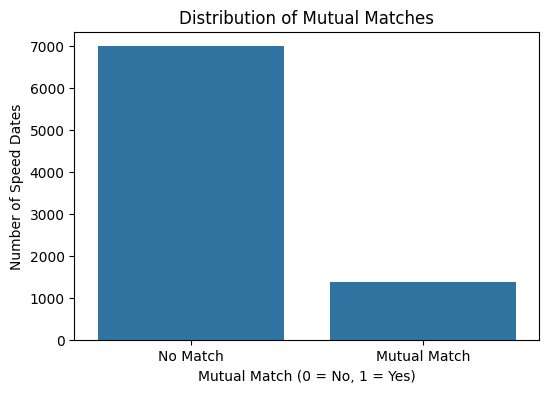

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="match")

plt.title("Distribution of Mutual Matches")
plt.xlabel("Mutual Match (0 = No, 1 = Yes)")
plt.ylabel("Number of Speed Dates")
plt.xticks([0, 1], ["No Match", "Mutual Match"])

plt.show()

### 4.2 Relationship Between Post-Date Ratings and Mutual Matches

We compare participants' post-date ratings across matched and
non-matched observations to identify potentially useful predictors.

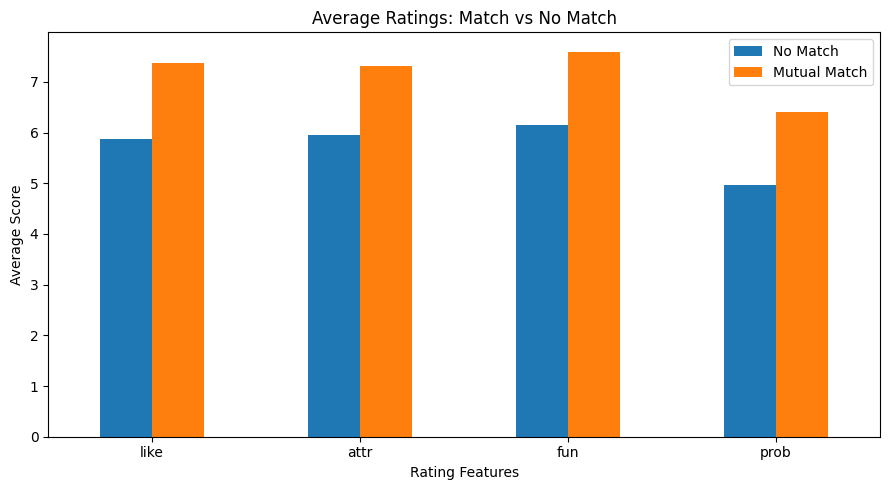

()

In [25]:

rating_features = ["like", "attr", "fun", "prob"]

match_rates = df.groupby("match")[rating_features].mean().T

match_rates.plot(kind="bar", figsize=(9, 5))

plt.title("Average Ratings: Match vs No Match")
plt.xlabel("Rating Features")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(["No Match", "Mutual Match"])
plt.tight_layout()
plt.show()
/

Just for example After the date, you rate:
- like = 8 → I liked this person quite a lot.
- attr = 7 → I found this person attractive.
- fun = 9 → I had fun.
- prob = 80 → I think there's an 80% chance that this person will say YES to another date.

In [26]:
X = df[candidate_features].copy()
y = df["match"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of features:", len(candidate_features))

X shape: (8378, 25)
y shape: (8378,)
Number of features: 25


In [27]:
print(df['iid'].isnull().sum())
print(df['pid'].isnull().sum())
print(df['wave'].isnull().sum())

0
10
0


So only pid have null entries so we need to exclude them from the valid row entries...

In [28]:

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# -----------------------------------
# 1. Create pair-level group IDs
# -----------------------------------

# Check that both participant IDs and wave are available
iid_num = pd.to_numeric(df["iid"], errors="coerce")
pid_num = pd.to_numeric(df["pid"], errors="coerce")
wave_num = pd.to_numeric(df["wave"], errors="coerce")

valid = (
    iid_num.notna()
    & pid_num.notna()
    & wave_num.notna()
)

groups = pd.Series(index=df.index, dtype="object")

# Normalize participant IDs so both directions get the same group
low = np.minimum(iid_num[valid], pid_num[valid]).astype(int)
high = np.maximum(iid_num[valid], pid_num[valid]).astype(int)

# Create pair group IDs
groups.loc[valid] = (
    wave_num[valid].astype(int).astype(str)
    + "_"
    + low.astype(str)
    + "_"
    + high.astype(str)
)

# Give incomplete rows separate group IDs
groups.loc[~valid] = (
    "incomplete_" + df.index[~valid].astype(str)
)

# -----------------------------------
# 2. First split: 60% train, 40% temp
# -----------------------------------

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.40,
    random_state=42
)

train_idx, temp_idx = next(
    splitter.split(X, y, groups=groups)
)

# -----------------------------------
# 3. Second split: 20% validation, 20% test
# -----------------------------------

X_temp = X.iloc[temp_idx]
y_temp = y.iloc[temp_idx]
groups_temp = groups.iloc[temp_idx]

splitter_temp = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_rel_idx, test_rel_idx = next(
    splitter_temp.split(
        X_temp,
        y_temp,
        groups=groups_temp
    )
)

# Map temporary indices to original indices
val_idx = temp_idx[val_rel_idx]
test_idx = temp_idx[test_rel_idx]

# -----------------------------------
# 4. Create final datasets
# -----------------------------------

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

# -----------------------------------
# 5. Check dataset sizes
# -----------------------------------

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# -----------------------------------
# 6. Check target distribution
# -----------------------------------

print("\nTarget distribution:")

print("Train:\n", y_train.value_counts(normalize=True).round(3))
print("Validation:\n", y_val.value_counts(normalize=True).round(3))
print("Test:\n", y_test.value_counts(normalize=True).round(3))

# -----------------------------------
# 7. Verify no pair overlap
# -----------------------------------

train_groups = set(groups.iloc[train_idx])
val_groups = set(groups.iloc[val_idx])
test_groups = set(groups.iloc[test_idx])

print("\nPair overlap checks:")

print("Train-Validation:", len(train_groups & val_groups))
print("Train-Test:", len(train_groups & test_groups))
print("Validation-Test:", len(val_groups & test_groups))

# -----------------------------------
# 8. Check incomplete rows
# -----------------------------------

print("\nIncomplete ID rows:", (~valid).sum())


Training: (5025, 25)
Validation: (1675, 25)
Testing: (1678, 25)

Target distribution:
Train:
 match
0    0.835
1    0.165
Name: proportion, dtype: float64
Validation:
 match
0    0.83
1    0.17
Name: proportion, dtype: float64
Test:
 match
0    0.841
1    0.159
Name: proportion, dtype: float64

Pair overlap checks:
Train-Validation: 0
Train-Test: 0
Validation-Test: 0

Incomplete ID rows: 10


Separate numerical and categorical features

In [29]:
categorical_features = [
    "gender", "samerace", "race", "race_o",
    "field_cd", "goal", "date", "go_out", "met"
]

numerical_features = [col for col in candidate_features if col not in categorical_features]

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Total features:", len(categorical_features) + len(numerical_features))

Categorical features: 9
Numerical features: 16
Total features: 25


Create numerical and categorical pipeline and their combination

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])



Create Logistic Regression model and Train the model

In [31]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("Preprocessor", preprocessor),
    ("Classifier", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'age_o', 'attr1_1',
                                                   'sinc1_1', 'intel1_1',
                                                   'fun1_1', 'amb1_1',
                                                   'shar1_1', 'attr', 'sinc',
                                                   'intel', 'fun', 'amb',
                                                   'shar', 'like', 'prob']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'samerace', 'race',
                                                   'race_o', 'field_cd', 'goal',
                                                   'date', 'go_out',
                                                   'met'])])),
                ('Classifier', LogisticRegression(max_iter=2000))])

In [32]:
y_pred = model.predict(X_val)

y_pred_proba = model.predict_proba(X_val)[:, 1]

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("Recall:", recall_score(y_val, y_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_pred_proba))
print("PR-AUC:", average_precision_score(y_val, y_pred_proba))

Accuracy: 0.84
Precision: 0.5833333333333334
Recall: 0.19718309859154928
ROC-AUC: 0.7853909944208746
PR-AUC: 0.4337399345881343


In [34]:
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.97      0.91      1391
           1       0.58      0.20      0.29       284

    accuracy                           0.84      1675
   macro avg       0.72      0.58      0.60      1675
weighted avg       0.81      0.84      0.81      1675



In [35]:
print(confusion_matrix(y_val, y_pred))

[[1351   40]
 [ 228   56]]


In [36]:
from sklearn.metrics import f1_score

thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

for threshold in thresholds:
    y_pred_threshold = (y_pred_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Predicted matches:", y_pred_threshold.sum())
    print("Precision:", round(precision_score(y_val, y_pred_threshold), 3))
    print("Recall:", round(recall_score(y_val, y_pred_threshold), 3))
    print("F1-score:", round(f1_score(y_val, y_pred_threshold), 3))


Threshold: 0.5
Predicted matches: 96
Precision: 0.583
Recall: 0.197
F1-score: 0.295

Threshold: 0.4
Predicted matches: 158
Precision: 0.475
Recall: 0.264
F1-score: 0.339

Threshold: 0.3
Predicted matches: 271
Precision: 0.435
Recall: 0.415
F1-score: 0.425

Threshold: 0.2
Predicted matches: 471
Precision: 0.367
Recall: 0.609
F1-score: 0.458

Threshold: 0.1
Predicted matches: 897
Precision: 0.275
Recall: 0.87
F1-score: 0.418


Best F1 in tested thresholds
 0.3

At threshold 0.3:
- The model identifies approximately 54% of actual mutual matches, compared with 28% at 0.5.
- Precision falls from 50% to 39.4%.
- F1 improves from 0.363 to 0.457.

In [37]:
balanced_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

balanced_model.fit(X_train, y_train)

y_balanced_pred = balanced_model.predict(X_val)
y_balanced_proba = balanced_model.predict_proba(X_val)[:, 1]

print("Accuracy:", accuracy_score(y_val, y_balanced_pred))
print("Precision:", precision_score(y_val, y_balanced_pred))
print("Recall:", recall_score(y_val, y_balanced_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_balanced_proba))
print("PR-AUC:", average_precision_score(y_val, y_balanced_proba))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_balanced_pred))

Accuracy: 0.7253731343283583
Precision: 0.34397163120567376
Recall: 0.6830985915492958
ROC-AUC: 0.7857504480513564
PR-AUC: 0.42397603923035104

Confusion Matrix:
[[1021  370]
 [  90  194]]


Compare both models

In [38]:
print("Original Logistic Regression")
print(classification_report(y_val, y_pred))

print("\nBalanced Logistic Regression")
print(classification_report(y_val, y_balanced_pred))

Original Logistic Regression
              precision    recall  f1-score   support

           0       0.86      0.97      0.91      1391
           1       0.58      0.20      0.29       284

    accuracy                           0.84      1675
   macro avg       0.72      0.58      0.60      1675
weighted avg       0.81      0.84      0.81      1675


Balanced Logistic Regression
              precision    recall  f1-score   support

           0       0.92      0.73      0.82      1391
           1       0.34      0.68      0.46       284

    accuracy                           0.73      1675
   macro avg       0.63      0.71      0.64      1675
weighted avg       0.82      0.73      0.76      1675



You can see that the F1 score is increase for our target thing "mutual_match"

In [39]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

models = {
    "Original Logistic Regression": y_pred_proba,
    "Balanced Logistic Regression": y_balanced_proba
}

model_comparison = []

for name, probabilities in models.items():

    model_comparison.append({
        "Model": name,
        "PR-AUC (Average Precision)": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

model_comparison = pd.DataFrame(model_comparison)

model_comparison.round(4)


,Model,PR-AUC (Average Precision),ROC-AUC
0,Original Logistic Regression,0.4337,0.7854
1,Balanced Logistic Regression,0.4240,0.7858


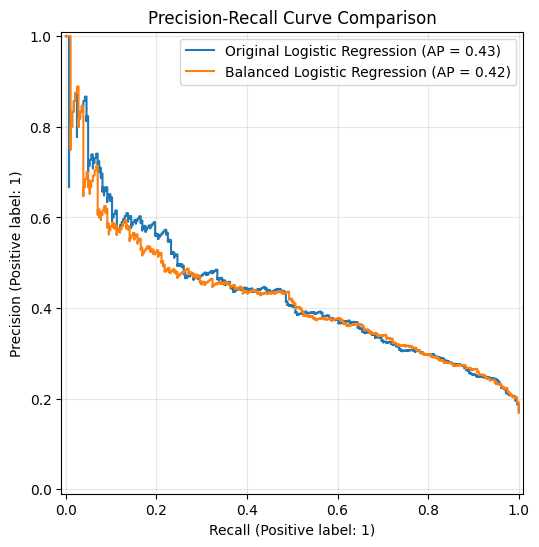

In [40]:

import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 6))

for name, probabilities in models.items():
    PrecisionRecallDisplay.from_predictions(
        y_val,
        probabilities,
        name=name,
        ax=ax
    )

ax.set_title("Precision-Recall Curve Comparison")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


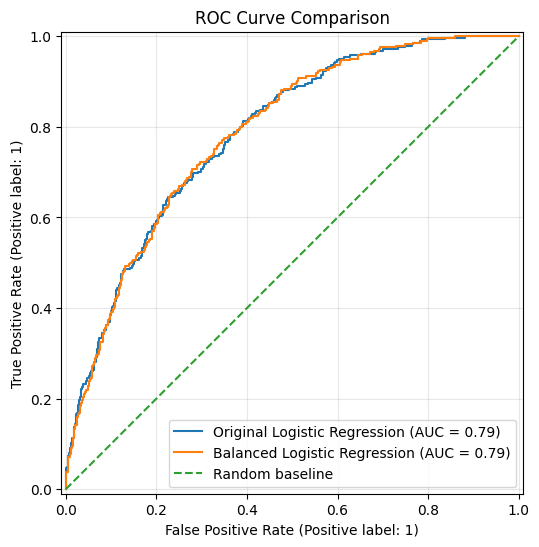

In [41]:

from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))

for name, probabilities in models.items():
    RocCurveDisplay.from_predictions(
        y_val,
        probabilities,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

ax.set_title("ROC Curve Comparison")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


I created a separate preprocessing pipeline because Logistic Regression requires feature scaling, whereas Random Forest does not. Both models need missing-value imputation and categorical encoding, but their numerical preprocessing requirements differ

In [42]:
from sklearn.ensemble import RandomForestClassifier


tree_numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

tree_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

tree_preprocessor = ColumnTransformer([
    ("numerical", tree_numerical_pipeline, numerical_features),
    ("categorical", tree_categorical_pipeline, categorical_features)
])




In [43]:

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)



y_rf_pred = rf_model.predict(X_val)
y_rf_proba = rf_model.predict_proba(X_val)[:, 1]

print("PR-AUC (Average Precision):",
      average_precision_score(y_val, y_rf_proba))

print("ROC-AUC:",
      roc_auc_score(y_val, y_rf_proba))

print("\nClassification Report:")
print(classification_report(y_val, y_rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_rf_pred))


PR-AUC (Average Precision): 0.5008318955593958
ROC-AUC: 0.8217793460981562

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.96      0.91      1391
           1       0.58      0.30      0.39       284

    accuracy                           0.84      1675
   macro avg       0.72      0.63      0.65      1675
weighted avg       0.82      0.84      0.82      1675


Confusion Matrix:
[[1329   62]
 [ 200   84]]


Untuned RF model results...

In [52]:

from sklearn.metrics import average_precision_score

# Predicted probabilities
y_rf_train_proba = rf_model.predict_proba(X_train)[:, 1]
y_rf_val_proba = rf_model.predict_proba(X_val)[:, 1]

# PR-AUC (Average Precision)
train_pr_auc = average_precision_score(y_train, y_rf_train_proba)
val_pr_auc = average_precision_score(y_val, y_rf_val_proba)

print(f"Training PR-AUC:   {train_pr_auc:.4f}")
print(f"Validation PR-AUC: {val_pr_auc:.4f}")
print(f"Overfitting gap:   {train_pr_auc - val_pr_auc:.4f}")


Training PR-AUC:   0.9913
Validation PR-AUC: 0.5008
Overfitting gap:   0.4905


In [44]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold



param_distributions = {
    "classifier__n_estimators": [150, 200, 300, 400],
    "classifier__max_depth": [3, 5, 8, 12],
    "classifier__min_samples_split": [2, 6, 10],
    "classifier__min_samples_leaf": [5, 10, 20, 40],
    "classifier__max_features": ["sqrt", 0.5],
    "classifier__class_weight": ["balanced", "balanced_subsample", None]
}

cv = GroupKFold(n_splits=3)

rf_search = RandomizedSearchCV(
    estimator=Pipeline([
        ("preprocessor", tree_preprocessor),
        ("classifier", RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ]),
    param_distributions=param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

train_groups = groups.iloc[train_idx]

rf_search.fit(
    X_train,
    y_train,
    groups=train_groups
)


print("Best CV PR-AUC:", rf_search.best_score_)
print("\nBest Parameters:")
print(rf_search.best_params_)


Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best CV PR-AUC: 0.44059074014587124

Best Parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 12, 'classifier__class_weight': 'balanced_subsample'}


In [45]:
best_index = rf_search.best_index_

print("Mean Training PR-AUC:",
      rf_search.cv_results_["mean_train_score"][best_index])

print("Mean Validation PR-AUC:",
      rf_search.cv_results_["mean_test_score"][best_index])


Mean Training PR-AUC: 0.7489229522434503
Mean Validation PR-AUC: 0.44059074014587124


In [46]:

best_index = rf_search.best_index_

print("Training PR-AUC:",
      rf_search.cv_results_["mean_train_score"][best_index])

print("CV PR-AUC:",
      rf_search.cv_results_["mean_test_score"][best_index])

print("CV Standard Deviation:",
      rf_search.cv_results_["std_test_score"][best_index])


Training PR-AUC: 0.7489229522434503
CV PR-AUC: 0.44059074014587124
CV Standard Deviation: 0.027623949542439005


In [47]:

tuned_rf_model = rf_search.best_estimator_

y_rf_pred = tuned_rf_model.predict(X_val)
y_rf_proba = tuned_rf_model.predict_proba(X_val)[:, 1]

print("Validation PR-AUC:",
      average_precision_score(y_val, y_rf_proba))

print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_rf_proba))

print("\nClassification Report:")
print(classification_report(y_val, y_rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_rf_pred))


Validation PR-AUC: 0.4778591222997659
Validation ROC-AUC: 0.8052976377314932

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.82      0.86      1391
           1       0.40      0.59      0.48       284

    accuracy                           0.78      1675
   macro avg       0.65      0.70      0.67      1675
weighted avg       0.82      0.78      0.80      1675


Confusion Matrix:
[[1141  250]
 [ 117  167]]


Preserve predictions from both Random Forest models

In [48]:

# Preserve probability predictions for both Random Forest models

y_rf_initial_proba = rf_model.predict_proba(X_val)[:, 1]

y_rf_tuned_proba = tuned_rf_model.predict_proba(X_val)[:, 1]


Evaluate all models at 101 thresholds
We will compare:
1. Original Logistic Regression
2. Balanced Logistic Regression
3. Initial Random Forest
4. Tuned Random Forest

In [49]:

from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Original Logistic Regression": y_pred_proba,
    "Balanced Logistic Regression": y_balanced_proba,
    "Initial Random Forest": y_rf_initial_proba,
    "Tuned Random Forest": y_rf_tuned_proba
}

thresholds = np.linspace(0, 1, 101)

def evaluate_thresholds(y_true, probabilities, model_name):
    results = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_true, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_true, predictions, zero_division=0
            )
        })

    return pd.DataFrame(results)


threshold_results_all = pd.concat(
    [
        evaluate_thresholds(y_val, probabilities, name)
        for name, probabilities in models.items()
    ],
    ignore_index=True
)

print("Total threshold evaluations:", len(threshold_results_all))


Total threshold evaluations: 404


Find the best F1 threshold for each model

In [50]:

best_thresholds = threshold_results_all.loc[
    threshold_results_all.groupby("Model")["F1"].idxmax()
].sort_values("F1", ascending=False).reset_index(drop=True)

best_thresholds


,Model,Threshold,Precision,Recall,F1
0,Initial Random Forest,0.25,0.385017,0.778169,0.515152
1,Tuned Random Forest,0.51,0.416459,0.588028,0.487591
2,Original Logistic Regression,0.19,0.368952,0.644366,0.469231
3,Balanced Logistic Regression,0.53,0.363458,0.651408,0.466583


Due to high overfitting on Untuned model we'll go with Tuned RF model with second highest F1 score

Combine training and validation data

In [54]:


X_train_val = pd.concat(
    [X_train, X_val],
    axis=0
)

y_train_val = pd.concat(
    [y_train, y_val],
    axis=0
)

print("Combined training shape:", X_train_val.shape)
print("Combined target shape:", y_train_val.shape)
print("Test shape:", X_test.shape)


Combined training shape: (6700, 25)
Combined target shape: (6700,)
Test shape: (1678, 25)


Retrain the tuned RF on 80%

In [55]:

final_model = clone(tuned_rf_model)

final_model.fit(X_train_val, y_train_val)

print("Final Tuned Random Forest trained successfully!")


Final Tuned Random Forest trained successfully!


Evaluate on the untouched test set

In [56]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities
y_test_proba = final_model.predict_proba(X_test)[:, 1]

# Threshold selected using validation data
final_threshold = 0.51

y_test_pred = (
    y_test_proba >= final_threshold
).astype(int)

# Threshold-independent metrics
test_ap = average_precision_score(y_test, y_test_proba)
test_roc_auc = roc_auc_score(y_test, y_test_proba)

# Threshold-dependent metrics
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)

print("FINAL TEST RESULTS")
print("-" * 35)
print(f"PR-AUC (Average Precision): {test_ap:.4f}")
print(f"ROC-AUC:                    {test_roc_auc:.4f}")
print(f"Precision:                  {test_precision:.4f}")
print(f"Recall:                     {test_recall:.4f}")
print(f"F1 Score:                   {test_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

FINAL TEST RESULTS
-----------------------------------
PR-AUC (Average Precision): 0.4091
ROC-AUC:                    0.8021
Precision:                  0.3844
Recall:                     0.6316
F1 Score:                   0.4780

Confusion Matrix:
[[1143  269]
 [  98  168]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.81      0.86      1412
           1       0.38      0.63      0.48       266

    accuracy                           0.78      1678
   macro avg       0.65      0.72      0.67      1678
weighted avg       0.84      0.78      0.80      1678

